In [26]:
import numpy as np
np.random.seed(0)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1) * 0.5

In [68]:
w=0.0
b=0.0
lr=0.1

In [69]:
loss_list = []
for epoch in range(1000):
    y_pred = w * X + b
    error = y_pred - y
    loss_list.append((error ** 2).mean())
    dw = 2 * (error * X).mean()
    db = 2 * error.mean()
    w -= lr * dw
    b -= lr * db

In [70]:
print(w, b)
print(loss_list)

2.9842337553505187 4.111075538723604
[np.float64(51.274504007331544), np.float64(17.9365331713545), np.float64(6.447199923764774), np.float64(2.4833262461462273), np.float64(1.1117638109079886), np.float64(0.633434485372697), np.float64(0.46312458581825416), np.float64(0.3992538172084463), np.float64(0.3723725408117295), np.float64(0.3585403306441194), np.float64(0.34949214755471447), np.float64(0.34236303406475166), np.float64(0.33614906511707454), np.float64(0.3304883723041555), np.float64(0.3252412411845129), np.float64(0.3203454258351745), np.float64(0.315766256478572), np.float64(0.3114793991123862), np.float64(0.30746486457392086), np.float64(0.30370489544304086), np.float64(0.3001831916814155), np.float64(0.29688460030328273), np.float64(0.29379496762926705), np.float64(0.29090105012478085), np.float64(0.2881904478403921), np.float64(0.2856515479076194), np.float64(0.28327347362508276), np.float64(0.2810460374624295), np.float64(0.2789596972797692), np.float64(0.2770055154025336

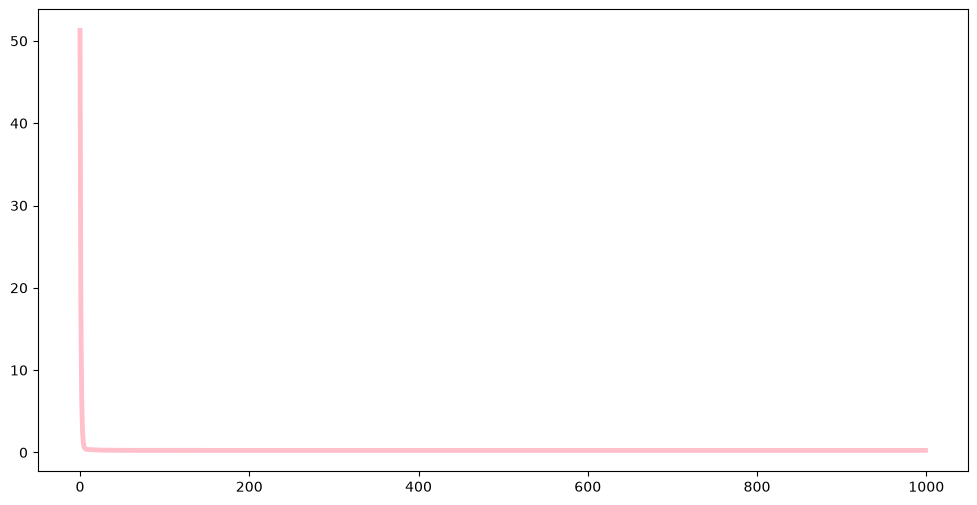

In [71]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(range(1000), loss_list, color="pink", linewidth=3.5)

In [43]:
from sklearn.linear_model import LinearRegression

reg = LinearRegression().fit(X, y)
print(reg.score(X, y))
print(reg.coef_)
print(reg.intercept_)


0.9226827678406244
[[2.98423376]]
[4.11107554]


## Régression linéaire à 2 variables d'entrée (version matricielle)

Modèle : $\hat{y} = w_1 x_1 + w_2 x_2 + b$

En ajoutant une colonne de 1 à $X$, on obtient $\hat{y} = X_b \theta$ avec $\theta = (b, w_1, w_2)^T$.

- Perte (MSE) : $L = \frac{1}{n}\|X_b\theta - y\|^2$
- Gradient : $\nabla_\theta L = \frac{2}{n} X_b^T (X_b\theta - y)$

In [72]:
np.random.seed(0)
n = 100
X2 = 2 * np.random.rand(n, 2)
y2 = 4 + 3 * X2[:, [0]] + 2 * X2[:, [1]] + np.random.randn(n, 1) * 0.5

# Ajout de la colonne de biais : X_b est de forme (n, 3)
X_b = np.c_[np.ones((n, 1)), X2]

In [73]:
theta = np.zeros((3, 1))  # [b, w1, w2]
lr = 0.1
loss_list2 = []

for epoch in range(1000):
    y_pred = X_b @ theta
    error = y_pred - y2
    loss_list2.append((error ** 2).mean())
    grad = (2 / n) * X_b.T @ error
    theta -= lr * grad

print(theta.ravel())

[4.05725162 2.89342511 2.00739377]


Text(0, 0.5, 'MSE')

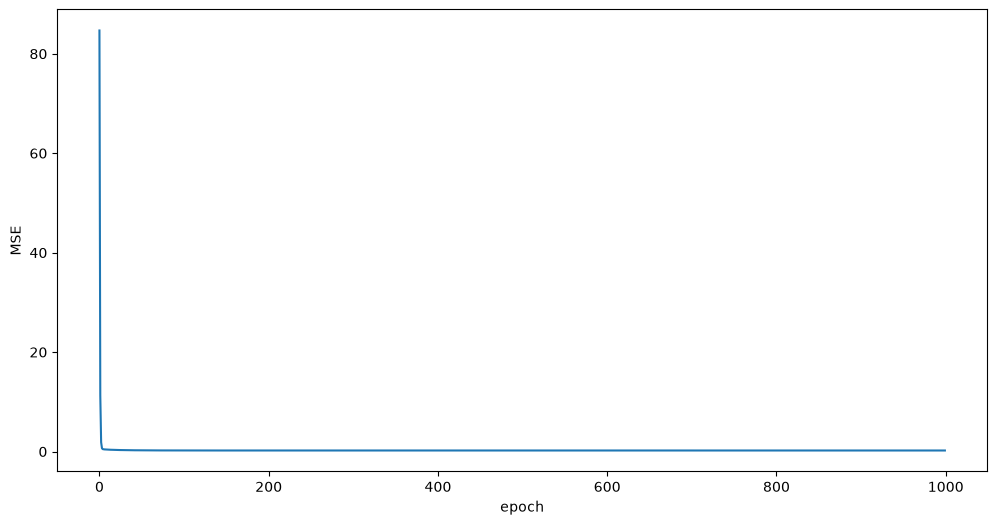

In [75]:
plt.figure(figsize=(12, 6))
plt.plot(range(1000), loss_list2)
plt.xlabel("epoch")
plt.ylabel("MSE")

In [76]:
reg2 = LinearRegression().fit(X2, y2)
print(reg2.score(X2, y2))
print(reg2.coef_)       # [w1, w2]
print(reg2.intercept_)  # b

# Solution exacte (équation normale)
theta_ne = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y2
print(theta_ne.ravel())

0.9461304888505465
[[2.89342511 2.00739377]]
[4.05725163]
[4.05725163 2.89342511 2.00739377]
